In [21]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [22]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), #크기를 변경하는 것부터 시작 
    transforms.Grayscale(1), # 흑백
    # transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [23]:
base_path = "/Users/kdt_0900_cjs/ml/resource/dataset"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "train")

In [24]:
train_dataset = ImageFolder(train_path, transform = train_transform)
test_dataset = ImageFolder(test_path, transform = test_transform)

print(len(train_dataset), len(test_dataset))

240 240


In [25]:
class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

## CNN을 활용해서 도형분류하기 실습

In [26]:
train_dataloader = DataLoader(train_dataset, batch_size = 64, shuffle = True)
test_dataloader = DataLoader(test_dataset, batch_size = 64, shuffle = False)

In [27]:
imgs, labels = next(iter(train_dataloader))

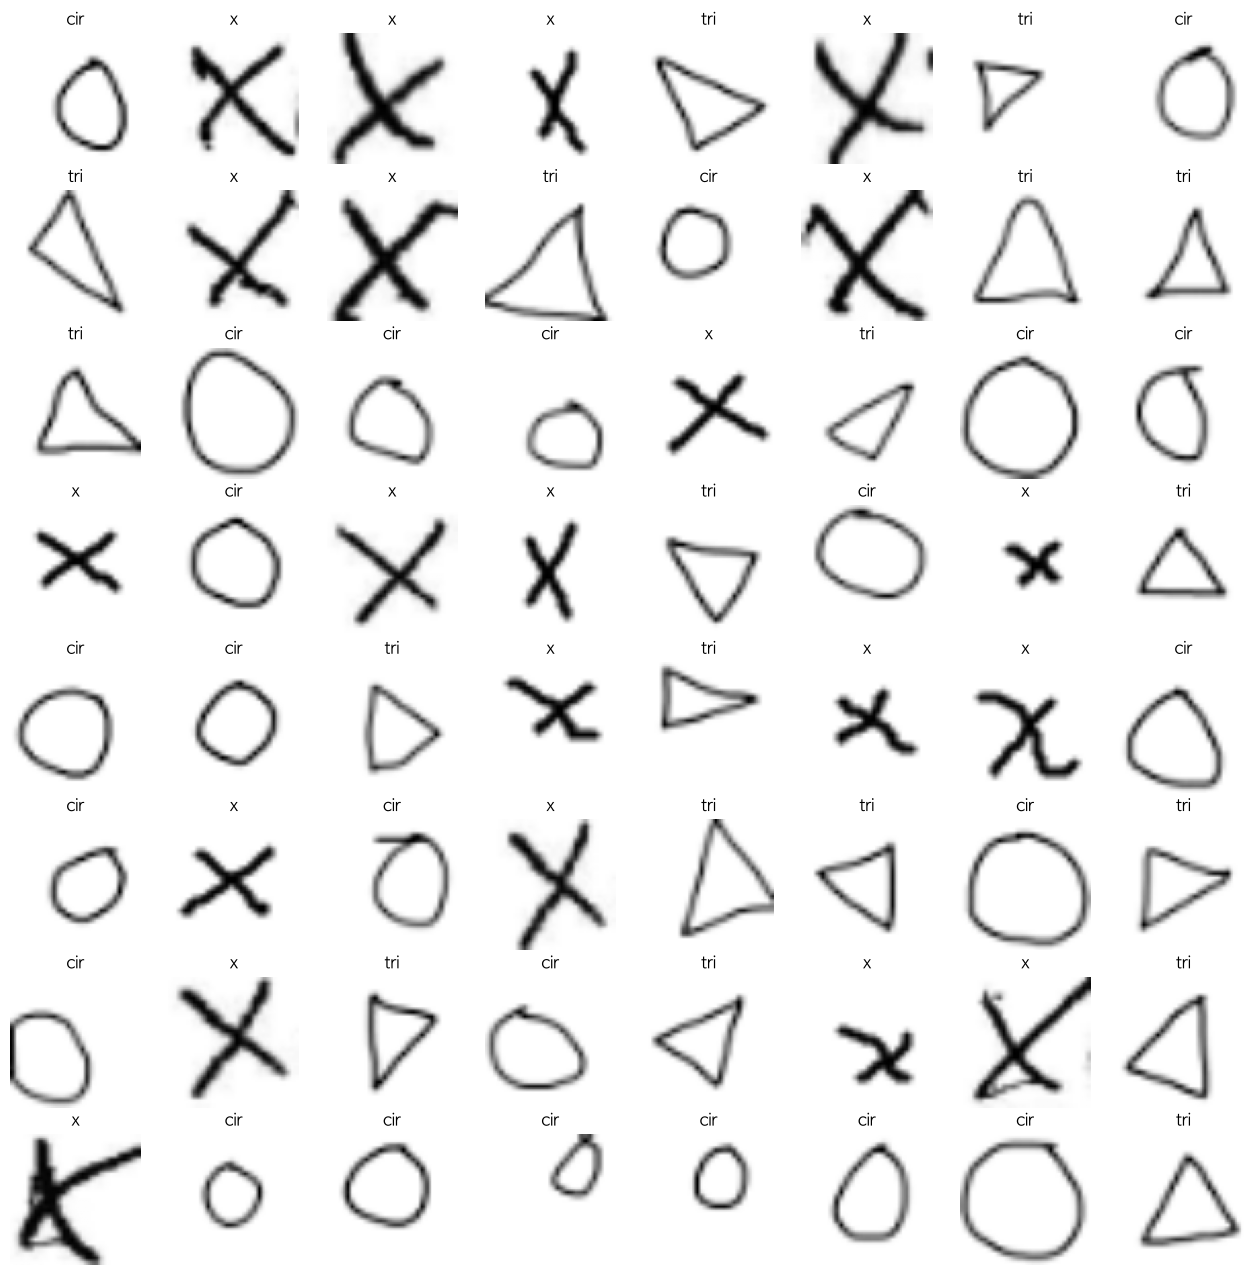

In [28]:
fig, axes = plt.subplots(8, 8, figsize=(16, 16))

for ax, img, label in zip(axes.flatten(), imgs, labels):
    ax.imshow(img.reshape(64, 64), cmap="gray")
    ax.set_title(class_dict[label.item()])
    ax.axis("off")


plt.show()

In [29]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [51]:
class ConvNenuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNenuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), # 64 64
            nn.ReLU(), # 활성화 함수
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 32 32
            nn.Dropout(0.1), # 과대적합을 없애는 목적
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), ## 16 16,
            nn.Dropout(0.25)
        )

        self.linear = nn.Linear(56 * 16 * 16, 10)
            
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [52]:
model = ConvNenuralNetwork().to(device)

In [53]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [54]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        #초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss {loss:.4f} | Accuracy : {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [55]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size

    return running_loss / total, running_corrects / total

In [56]:
epochs = 50

for i in range(epochs):
    #학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader = train_dataloader,
        criterion = criterion,
        optimizer = optimizer,
        device=device
    )

    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc}")

Epoch: 0/50
[Train] Loss: 1.7090 | Accuracy: 0.3
[Test] Loss: 1.0706 | Accuracy: 0.6291666666666667
Epoch: 1/50
[Train] Loss: 1.1528 | Accuracy: 0.43333333333333335
[Test] Loss: 0.9397 | Accuracy: 0.625
Epoch: 2/50
[Train] Loss: 0.9340 | Accuracy: 0.475
[Test] Loss: 0.6988 | Accuracy: 0.6583333333333333
Epoch: 3/50
[Train] Loss: 0.6203 | Accuracy: 0.6625
[Test] Loss: 0.5082 | Accuracy: 0.8125
Epoch: 4/50
[Train] Loss: 0.4770 | Accuracy: 0.7458333333333333
[Test] Loss: 0.4365 | Accuracy: 0.7208333333333333
Epoch: 5/50
[Train] Loss: 0.4064 | Accuracy: 0.7875
[Test] Loss: 0.3386 | Accuracy: 0.85
Epoch: 6/50
[Train] Loss: 0.3144 | Accuracy: 0.8541666666666666
[Test] Loss: 0.2913 | Accuracy: 0.8625
Epoch: 7/50
[Train] Loss: 0.2897 | Accuracy: 0.8666666666666667
[Test] Loss: 0.2274 | Accuracy: 0.8875
Epoch: 8/50
[Train] Loss: 0.2495 | Accuracy: 0.9
[Test] Loss: 0.1869 | Accuracy: 0.9291666666666667
Epoch: 9/50
[Train] Loss: 0.1902 | Accuracy: 0.925
[Test] Loss: 0.1761 | Accuracy: 0.925
Epoch

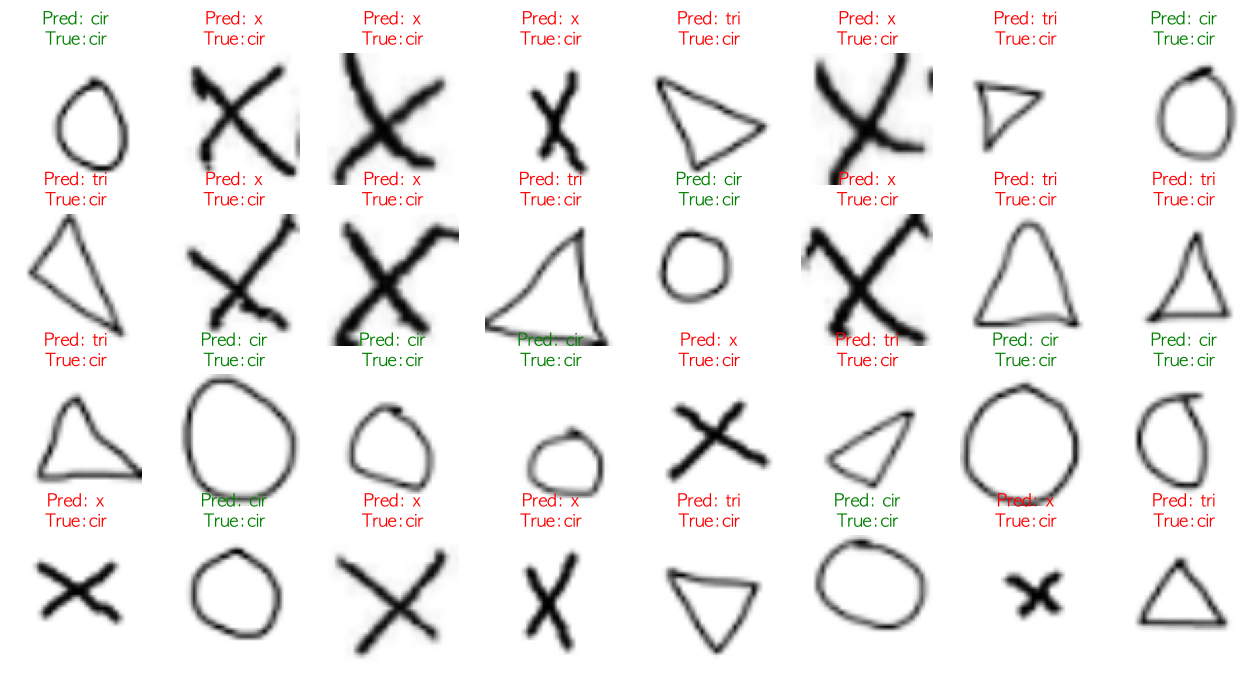

In [57]:
model.eval()

lmgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu=imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color= "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue:{true_label}", color=color)

plt.show()